# Лабораторная работа № 1

## Простая математическая модель: дискретная динамика

## 1. Математическая модель

Пользователи разделены на три группы:

- $S_t$ - ещё не получили информацию;
- $I_t$ - распространяют информацию;
- $R_t$ - перестали её распространять.

Модель задаётся уравнениями:

$$S_{t+1}=S_t-\beta S_tI_t,$$

$$I_{t+1}=I_t+\beta S_tI_t-\gamma I_t,$$

$$R_{t+1}=R_t+\gamma I_t.$$

$\beta$ определяет скорость передачи информации, а $\gamma$ - скорость прекращения распространения.


## 2. Параметры и функция моделирования

In [114]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"

N = 1000
S0, I0, R0 = 990, 10, 0
beta = 0.0005
gamma = 0.1
steps = 100


def simulate(beta, gamma, S0=S0, I0=I0, R0=R0, steps=steps):
    S = np.zeros(steps + 1)
    I = np.zeros(steps + 1)
    R = np.zeros(steps + 1)
    S[0], I[0], R[0] = S0, I0, R0

    for t in range(steps):
        new_informed = beta * S[t] * I[t]
        stopped = gamma * I[t]

        S[t + 1] = S[t] - new_informed
        I[t + 1] = I[t] + new_informed - stopped
        R[t + 1] = R[t] + stopped

    return S, I, R


Функция буквально повторяет три разностных уравнения. На каждом шаге сначала вычисляются число новых информированных и число прекративших распространение, затем обновляются $S$, $I$ и $R$.


## 3. Базовый расчёт

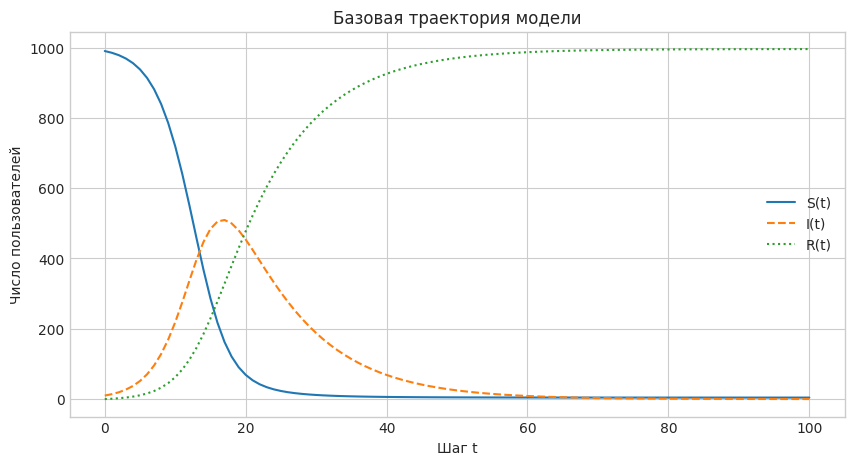

Пик I = 509.40, шаг пика = 17
Охват к шагу 100 = 99.57% - 996 пользователей


In [115]:
S, I, R = simulate(beta, gamma)
t = np.arange(steps + 1)

peak_step = np.argmax(I)
peak_value = I[peak_step]
coverage = (N - S[-1]) / N * 100

plt.figure(figsize=(10, 5))
plt.plot(t, S, label="S(t)")
plt.plot(t, I, "--", label="I(t)")
plt.plot(t, R, ":", label="R(t)")
plt.xlabel("Шаг t")
plt.ylabel("Число пользователей")
plt.title("Базовая траектория модели")
plt.legend()
plt.show()

print(f"Пик I = {peak_value:.2f}, шаг пика = {peak_step}")
print(f"Охват к шагу 100 = {coverage:.2f}% - {R[-1] + I[-1]:.0f} пользователей")


### Результат базового расчёта

Количество распространяющих информацию достигает максимума **509.40 пользователя на шаге 17**. К шагу 100 информация охватывает **99.57% сети**.

В начале $\beta S_0>\gamma$, поэтому $I_t$ растёт. После уменьшения числа неинформированных скорость появления новых распространителей падает и $I_t$ начинает уменьшаться.


## 4. Эксперименты с параметрами

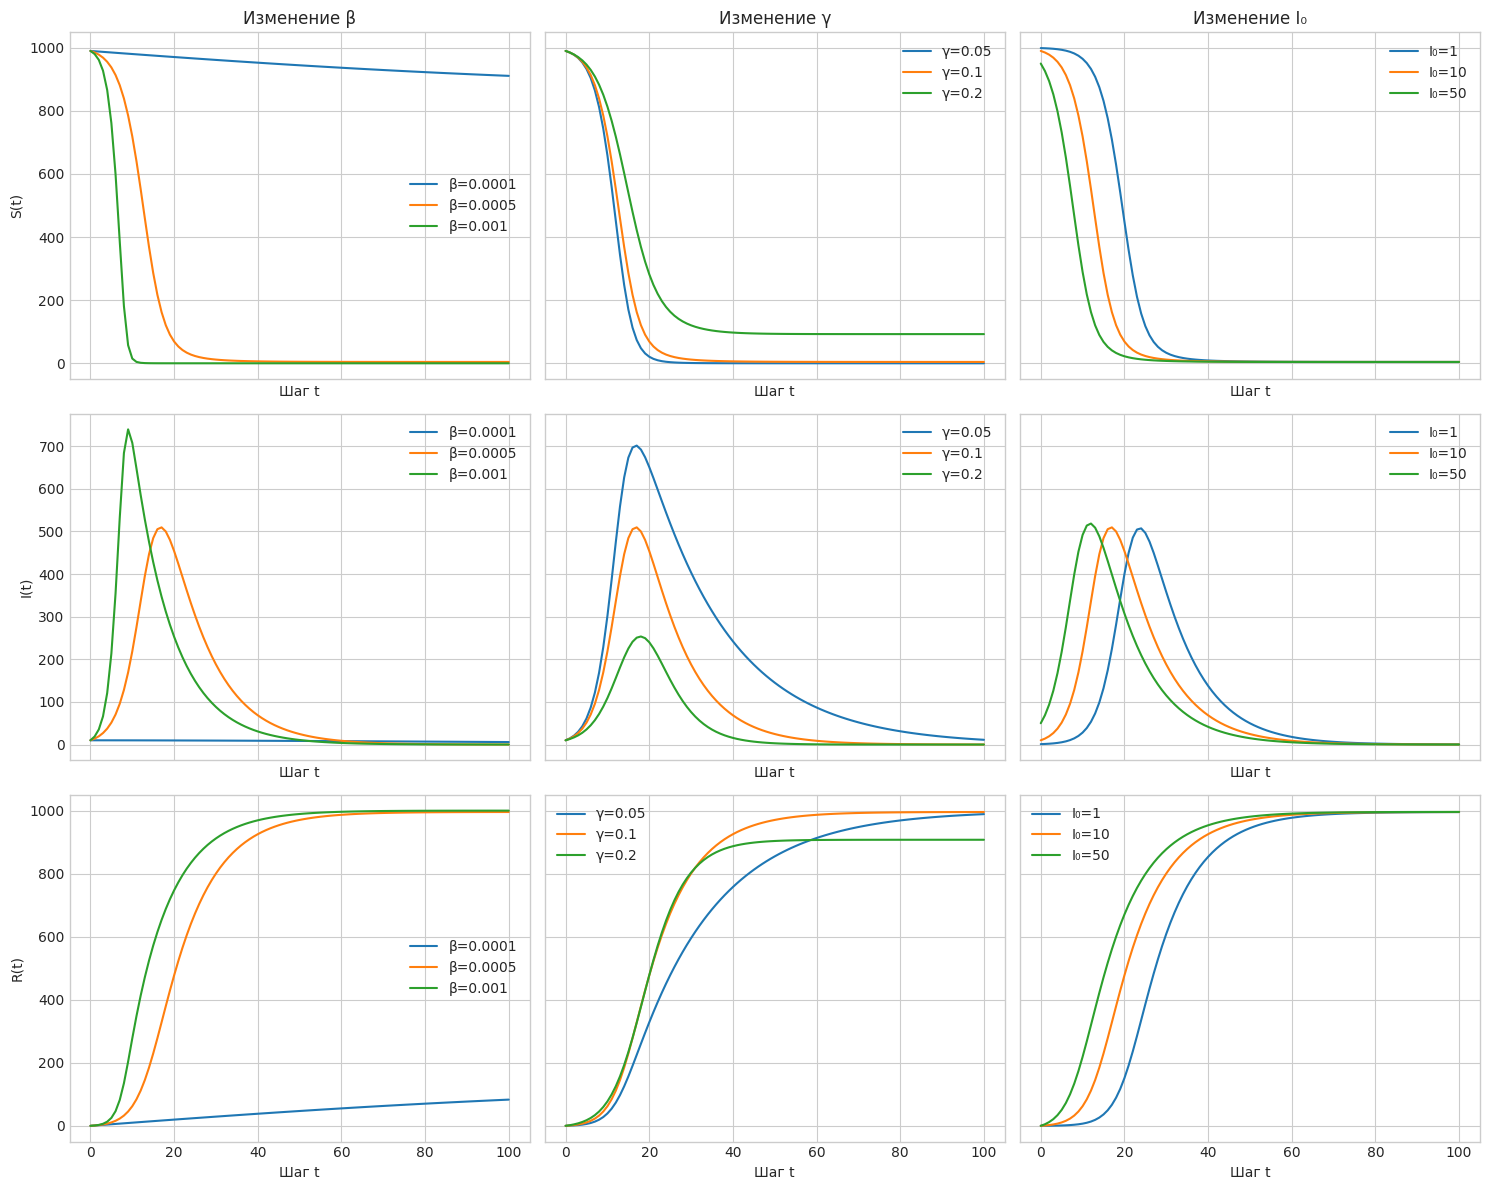

In [116]:
fig, axes = plt.subplots(
    3, 3,
    figsize=(15, 12),
    sharex=True,
    sharey="row"
)

# Изменение beta
for value in [0.0001, 0.0005, 0.001]:
    S_test, I_test, R_test = simulate(value, gamma)

    axes[0, 0].plot(t, S_test, label=f"β={value}")
    axes[1, 0].plot(t, I_test, label=f"β={value}")
    axes[2, 0].plot(t, R_test, label=f"β={value}")

# Изменение gamma
for value in [0.05, 0.1, 0.2]:
    S_test, I_test, R_test = simulate(beta, value)

    axes[0, 1].plot(t, S_test, label=f"γ={value}")
    axes[1, 1].plot(t, I_test, label=f"γ={value}")
    axes[2, 1].plot(t, R_test, label=f"γ={value}")

# Изменение начального I0
for value in [1, 10, 50]:
    S_test, I_test, R_test = simulate(
        beta,
        gamma,
        S0=N - value,
        I0=value
    )

    axes[0, 2].plot(t, S_test, label=f"I₀={value}")
    axes[1, 2].plot(t, I_test, label=f"I₀={value}")
    axes[2, 2].plot(t, R_test, label=f"I₀={value}")

# Заголовки столбцов
axes[0, 0].set_title("Изменение β")
axes[0, 1].set_title("Изменение γ")
axes[0, 2].set_title("Изменение I₀")

# Подписи строк
axes[0, 0].set_ylabel("S(t)")
axes[1, 0].set_ylabel("I(t)")
axes[2, 0].set_ylabel("R(t)")

# Оформление всех графиков
for ax in axes.flat:
    ax.set_xlabel("Шаг t")
    ax.legend()

plt.tight_layout()
plt.show()

In [117]:
experiments = []

for name, b, g, initial_i in [
    ("β=0.0001", 0.0001, gamma, I0),
    ("β=0.0005", 0.0005, gamma, I0),
    ("β=0.0010", 0.0010, gamma, I0),
    ("γ=0.05", beta, 0.05, I0),
    ("γ=0.10", beta, 0.10, I0),
    ("γ=0.20", beta, 0.20, I0),
    ("I₀=1", beta, gamma, 1),
    ("I₀=10", beta, gamma, 10),
    ("I₀=50", beta, gamma, 50),
]:
    S_test, I_test, R_test = simulate(b, g, S0=N-initial_i, I0=initial_i)
    experiments.append([
        name,
        I_test.max(),
        np.argmax(I_test),
        (N - S_test[-1]) / N * 100,
        round(N - S_test[-1]),
    ])

table = pd.DataFrame(
    experiments,
    columns=["Сценарий", "Пик I", "Шаг пика", "Охват, %", "Охват, Пользователи"],
)
print(table.round(2).to_string(index=False))


Сценарий  Пик I  Шаг пика  Охват, %  Охват, Пользователи
β=0.0001  10.00         0      8.90                   89
β=0.0005 509.40        17     99.57                  996
β=0.0010 739.27         9    100.00                 1000
  γ=0.05 701.19        17    100.00                 1000
  γ=0.10 509.40        17     99.57                  996
  γ=0.20 253.48        18     90.75                  908
    I₀=1 507.05        24     99.56                  996
   I₀=10 509.40        17     99.57                  996
   I₀=50 518.36        12     99.59                  996


### Вывод по экспериментам

- При увеличении $\beta$ информация распространяется быстрее, пик $I_t$ становится выше, а охват увеличивается.
- При увеличении $\gamma$ пользователи быстрее прекращают распространение, поэтому пик и итоговый охват уменьшаются.
- Увеличение $I_0$ сдвигает пик на более ранний шаг, но при базовых $\beta$ и $\gamma$ итоговый охват меняется незначительно.
- Информация быстро затухает, если $\beta S_0<\gamma$.
- Долгий хвост появляется, когда после пика величина $\beta S_t-\gamma$ остаётся близкой к нулю.


## 5. Верификация модели

,Шаг,S,I,R,S + I + R,Отклонение от N,Абсолютная ошибка,Относительная ошибка,Все значения >= 0
0,0,990.000000,10.000000,0.000000,1000.000000000000,0.000e+00,0.000e+00,0.000e+00,True
1,1,985.050000,13.950000,1.000000,1000.000000000000,0.000e+00,0.000e+00,0.000e+00,True
2,2,978.179276,19.425724,2.395000,1000.000000000000,-1.137e-13,1.137e-13,1.137e-16,True
3,3,968.678356,26.984072,4.337572,1000.000000000000,0.000e+00,0.000e+00,0.000e+00,True
4,4,955.608913,37.355107,7.035980,1000.000000000000,-1.137e-13,1.137e-13,1.137e-16,True
5,5,937.760476,51.468034,10.771490,1000.000000000000,-1.137e-13,1.137e-13,1.137e-16,True
6,6,913.628132,70.453574,15.918294,1000.000000000000,0.000e+00,0.000e+00,0.000e+00,True
7,7,881.443949,95.592400,22.963651,1000.000000000000,-1.137e-13,1.137e-13,1.137e-16,True
8,8,839.314277,128.162832,32.522891,1000.000000000000,0.000e+00,0.000e+00,0.000e+00,True
9,9,785.529830,169.130996,45.339174,1000.000000000000,-1.137e-13,1.137e-13,1.137e-16,True


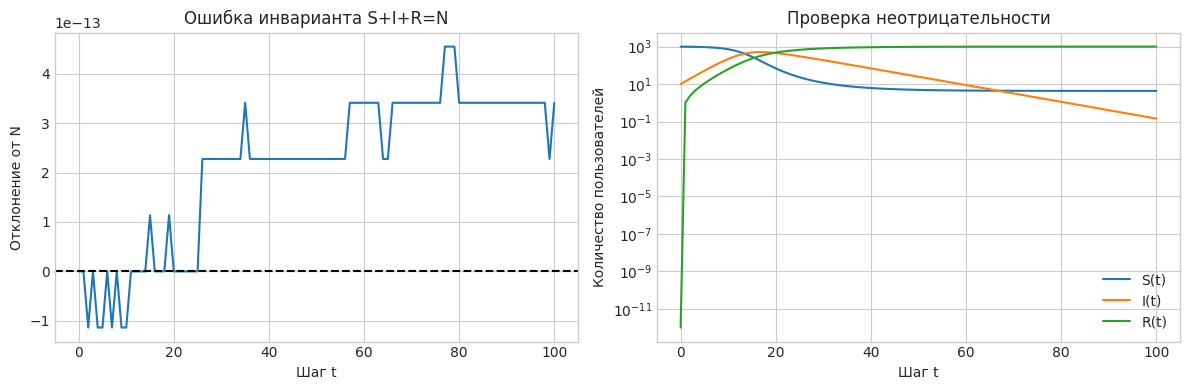

Максимальная абсолютная ошибка: 4.547e-13
Максимальная относительная ошибка: 4.547e-16
Все значения неотрицательны: True


In [118]:
verification_table = pd.DataFrame({
    "Шаг": t,
    "S": S,
    "I": I,
    "R": R,
})

# Проверка суммы пользователей
verification_table["S + I + R"] = (
    verification_table["S"]
    + verification_table["I"]
    + verification_table["R"]
)

# Ошибки инварианта
verification_table["Отклонение от N"] = (
    verification_table["S + I + R"] - N
)

verification_table["Абсолютная ошибка"] = np.abs(
    verification_table["Отклонение от N"]
)

verification_table["Относительная ошибка"] = (
    verification_table["Абсолютная ошибка"] / N
)

# Проверка неотрицательности на каждом шаге
verification_table["Все значения >= 0"] = (
    (verification_table["S"] >= 0)
    & (verification_table["I"] >= 0)
    & (verification_table["R"] >= 0)
)

# Итоговые показатели
max_absolute_error = verification_table["Абсолютная ошибка"].max()
max_relative_error = verification_table["Относительная ошибка"].max()
all_nonnegative = verification_table["Все значения >= 0"].all()

# Вывод полной таблицы
display(
    verification_table.style.format({
        "S": "{:.6f}",
        "I": "{:.6f}",
        "R": "{:.6f}",
        "S + I + R": "{:.12f}",
        "Отклонение от N": "{:.3e}",
        "Абсолютная ошибка": "{:.3e}",
        "Относительная ошибка": "{:.3e}",
    })
)

# Построение графиков
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    verification_table["Шаг"],
    verification_table["Отклонение от N"]
)
axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("Ошибка инварианта S+I+R=N")
axes[0].set_xlabel("Шаг t")
axes[0].set_ylabel("Отклонение от N")

axes[1].semilogy(t, np.maximum(S, 1e-12), label="S(t)")
axes[1].semilogy(t, np.maximum(I, 1e-12), label="I(t)")
axes[1].semilogy(t, np.maximum(R, 1e-12), label="R(t)")
axes[1].set_title("Проверка неотрицательности")
axes[1].set_xlabel("Шаг t")
axes[1].set_ylabel("Количество пользователей")
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Максимальная абсолютная ошибка: {max_absolute_error:.3e}")
print(f"Максимальная относительная ошибка: {max_relative_error:.3e}")
print(f"Все значения неотрицательны: {all_nonnegative}")

### Проверка граничных случаев

In [119]:
# I0 = 0
S_a, I_a, R_a = simulate(beta, gamma, S0=N, I0=0)

test_I0 = (
    np.allclose(S_a, N)
    and np.allclose(I_a, 0)
    and np.allclose(R_a, 0)
)

# beta = 0
S_b, I_b, R_b = simulate(0, gamma)

test_beta = (
    np.allclose(S_b, S0)
    and np.allclose(I_b[1:], (1 - gamma) * I_b[:-1])
)

# gamma = 1
S_c, I_c, R_c = simulate(beta, 1)

test_gamma = (
    np.allclose(I_c[1:], beta * S_c[:-1] * I_c[:-1])
    and np.allclose(R_c[1:] - R_c[:-1], I_c[:-1])
)

tests = pd.DataFrame({
    "Проверка": ["I₀=0", "β=0", "γ=1"],
    "Ожидаемое поведение": [
        "Информация не распространяется",
        "Новые информированные не появляются",
        "Все текущие I переходят в R за один шаг",
    ],
    "Результат": [
        test_I0,
        test_beta,
        test_gamma,
    ],
})

display(tests)

,Проверка,Ожидаемое поведение,Результат
0,I₀=0,Информация не распространяется,True
1,β=0,Новые информированные не появляются,True
2,γ=1,Все текущие I переходят в R за один шаг,True


### Проверка предельных режимов

### Результат верификации

Максимальное относительное отклонение от $N$ равно **$4.55\cdot10^{-16}$**, что намного меньше допустимого значения $10^{-6}$. Все значения $S_t$, $I_t$ и $R_t$ неотрицательны. Граничные проверки $I_0=0$, $\beta=0$ и $\gamma=1$ выполнены успешно.

Небольшое отклонение от инварианта объясняется округлением вещественных чисел. При слишком большом $\beta$ явная схема может дать отрицательное $S_t$. В таком случае следует уменьшить шаг моделирования.

При $\gamma=1$ пользователи из $I_t$ переходят в $R$, но перед этим могут создать новых информированных. Поэтому по заданным уравнениям $I_{t+1}=\beta S_tI_t$, а не обязательно ноль.


## 6. Валидация по псевдореальным данным

β,0.000100,0.000200,0.000300,0.000400,0.000500,0.000600,0.000700,0.000800,0.000900,0.001000
γ,,,,,,,,,,
0.050000,35261.19,62199.22,55034.03,41935.72,31553.43,25420.08,22737.23,22266.51,22995.64,24271.88
0.060000,29546.52,49193.67,42986.71,30841.67,21088.86,15408.65,13100.98,12964.89,13995.07,15536.99
0.070000,27428.02,40782.36,35256.54,23916.91,14694.79,9386.20,7383.69,7523.01,8804.81,10571.16
0.080000,26908.72,35241.04,30168.73,19497.74,10714.67,5704.70,3945.87,4309.03,5799.74,7755.20
0.090000,26957.37,31580.42,26795.83,16677.85,8251.89,3475.24,1905.66,2447.43,4109.93,6224.10
0.100000,27153.17,29192.04,24583.72,14926.23,6786.44,2184.90,755.92,1436.12,3237.76,5484.23
0.110000,27360.88,27681.14,23180.66,13913.01,5999.85,1522.09,190.06,972.62,2884.31,5239.86
0.120000,27546.58,26781.08,22352.39,13423.20,5688.30,1289.79,15.60,867.88,2863.41,5307.36
0.130000,27705.61,26306.15,21936.75,13310.98,5716.43,1359.23,108.07,1000.44,3055.97,5569.68


Проверено пар параметров: 160
Лучшее β: 0.0007
Лучшее γ: 0.12
Минимальная MSE: 15.597


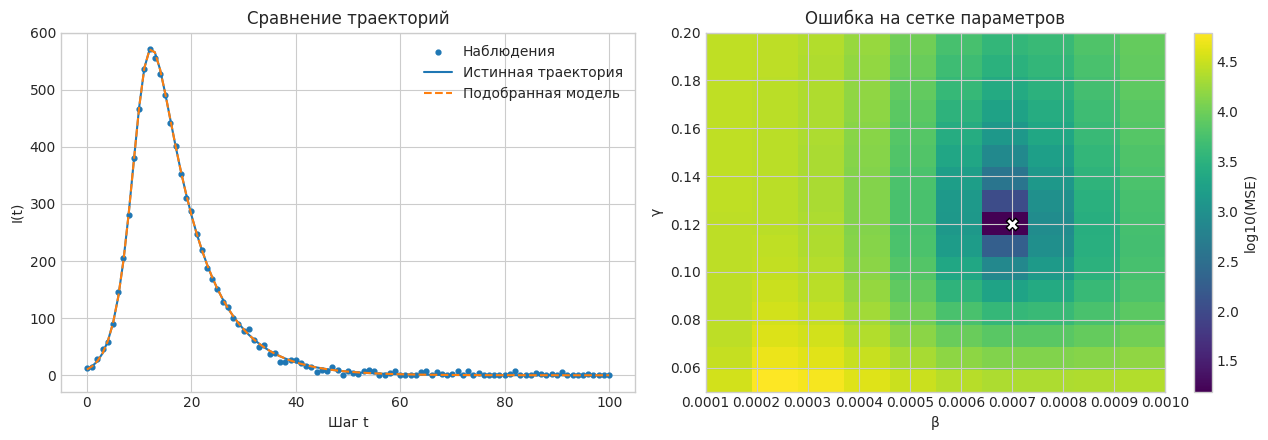

In [120]:
true_beta = 0.0007
true_gamma = 0.12

np.random.seed(42)
_, true_I, _ = simulate(true_beta, true_gamma)
observed_I = np.maximum(true_I + np.random.normal(0, 5, len(true_I)), 0)

beta_values = np.round(
    np.arange(0.0001, 0.0011, 0.0001),
    4
)

gamma_values = np.round(
    np.arange(0.05, 0.201, 0.01),
    2
)

grid_results = []

for b in beta_values:
    for g in gamma_values:
        _, model_I, _ = simulate(b, g)

        mse = np.mean(
            (model_I - observed_I) ** 2
        )

        grid_results.append([
            b,
            g,
            mse,
        ])

grid_results = pd.DataFrame(
    grid_results,
    columns=["β", "γ", "MSE"],
)

# Таблица MSE для всех 160 пар параметров
mse_table = grid_results.pivot(
    index="γ",
    columns="β",
    values="MSE",
)

display(
    mse_table.style
    .format("{:.2f}")
    .background_gradient(
        cmap="viridis_r",
        axis=None
    )
)

# Поиск пары с минимальной MSE
best_index = grid_results["MSE"].idxmin()
best_result = grid_results.loc[best_index]

best_beta = best_result["β"]
best_gamma = best_result["γ"]
best_mse = best_result["MSE"]

beta_values = mse_table.columns.to_numpy()
gamma_values = mse_table.index.to_numpy()
errors = mse_table.to_numpy()

print(f"Проверено пар параметров: {len(grid_results)}")
print(f"Лучшее β: {best_beta:.4f}")
print(f"Лучшее γ: {best_gamma:.2f}")
print(f"Минимальная MSE: {best_mse:.3f}")

_, fitted_I, _ = simulate(best_beta, best_gamma)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].scatter(t, observed_I, s=12, label="Наблюдения")
axes[0].plot(t, true_I, label="Истинная траектория")
axes[0].plot(t, fitted_I, "--", label="Подобранная модель")
axes[0].set_title("Сравнение траекторий")
axes[0].set_xlabel("Шаг t")
axes[0].set_ylabel("I(t)")
axes[0].legend()

heatmap = axes[1].imshow(
    np.log10(errors),
    origin="lower",
    aspect="auto",
    cmap="viridis",
    extent=[beta_values[0], beta_values[-1], gamma_values[0], gamma_values[-1]],
)
axes[1].scatter(best_beta, best_gamma, color="white", edgecolor="black", marker="X", s=80)
axes[1].set_title("Ошибка на сетке параметров")
axes[1].set_xlabel("β")
axes[1].set_ylabel("γ")
plt.colorbar(heatmap, ax=axes[1], label="log10(MSE)")

plt.tight_layout()
plt.show()


### Результат валидации

Истинные параметры были заданы как $\beta^*=0.0007$ и $\gamma^*=0.12$. Перебор по сетке восстановил те же значения: **$\hat\beta=0.0007$ и $\hat\gamma=0.12$**.

Подбор оказался успешным, потому что истинные параметры входят в сетку, шум небольшой, а вся траектория содержит информацию и о росте, и о затухании. На реальных данных возникнут дополнительные сложности: пропуски, неоднородность пользователей, изменение параметров во времени и неполнота наблюдений.


## 7. Итоговый вывод

Дискретная SIR-модель позволяет описать распространение информации между пользователями. Программа сохраняет общее число пользователей и корректно проходит граничные проверки. Эксперименты показали, что $\beta$ усиливает распространение, $\gamma$ подавляет его, а $I_0$ влияет главным образом на время достижения пика. Сеточный поиск успешно восстановил параметры по зашумлённой траектории.
